# CS412 Week 7 - Facial Emotion Recognition (FER2013)
**Name:** Jhey Gulde

**Course & Section:** CS412 - CS4A

**Roles:** Individual work. I did the data checking, face detection, feature extraction, model training, evaluation and the write-up.

**Track:** Track B - CNN deep features (MobileNetV2)

**Models:** Logistic Regression and SVM (RBF kernel)

In [1]:
# packages are already installed on my laptop, uncomment if running somewhere else
# %pip install opencv-python numpy pandas matplotlib scikit-learn torch torchvision

In [2]:
import os
import time
import random
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [3]:
TRAIN_DIR = "data/train"
TEST_DIR = "data/test"
HAAR_FILE = "models/haarcascade_frontalface_default.xml"
OUTPUT_DIR = "OUTPUTS"
FEATURE_DIR = "features"
UNSEEN_DIR = "unseen_images"

EMOTIONS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# save the downloaded MobileNetV2 weights inside the project folder
torch.hub.set_dir("models/torch_hub")

## Sanity Check
Before starting I checked that the 7 emotion folders are in both `data/train` and `data/test`, counted the images per class, and looked at some samples.

In [4]:
for folder in [TRAIN_DIR, TEST_DIR]:
    for emo in EMOTIONS:
        path = os.path.join(folder, emo)
        if not os.path.isdir(path):
            print("MISSING:", path)
print("Folder check done, all 7 classes found in train and test")

Folder check done, all 7 classes found in train and test


In [5]:
def load_file_list(folder):
    paths = []
    labels = []
    for emo in EMOTIONS:
        emo_folder = os.path.join(folder, emo)
        for f in sorted(os.listdir(emo_folder)):
            paths.append(os.path.join(emo_folder, f))
            labels.append(emo)
    return paths, labels

train_paths, train_labels = load_file_list(TRAIN_DIR)
test_paths, test_labels = load_file_list(TEST_DIR)

counts = pd.DataFrame({
    "train": pd.Series(train_labels).value_counts(),
    "test": pd.Series(test_labels).value_counts(),
}).loc[EMOTIONS]
counts["total"] = counts["train"] + counts["test"]
print(counts)
print()
print("Total train images:", len(train_paths))
print("Total test images:", len(test_paths))

          train  test  total
angry      3995   958   4953
disgust     436   111    547
fear       4097  1024   5121
happy      7215  1774   8989
sad        4830  1247   6077
surprise   3171   831   4002
neutral    4965  1233   6198

Total train images: 28709
Total test images: 7178


In [6]:
# check if the images are really 48x48 grayscale
for p in random.sample(train_paths, 5):
    img = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    print(os.path.basename(p), img.shape, img.dtype)

Training_2053636.jpg (48, 48) uint8
Training_9294862.jpg (48, 48) uint8
Training_28360608.jpg (48, 48) uint8
Training_19381766.jpg (48, 48) uint8
Training_15918415.jpg (48, 48) uint8


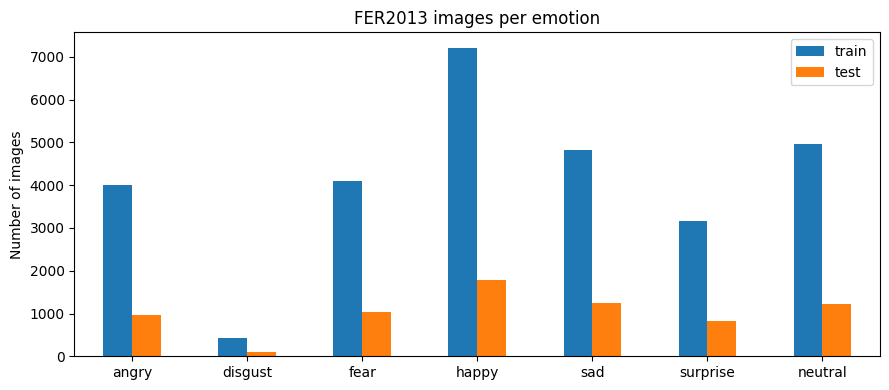

In [7]:
counts[["train", "test"]].plot(kind="bar", figsize=(9, 4), rot=0)
plt.title("FER2013 images per emotion")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/class_distribution.png", dpi=150)
plt.show()

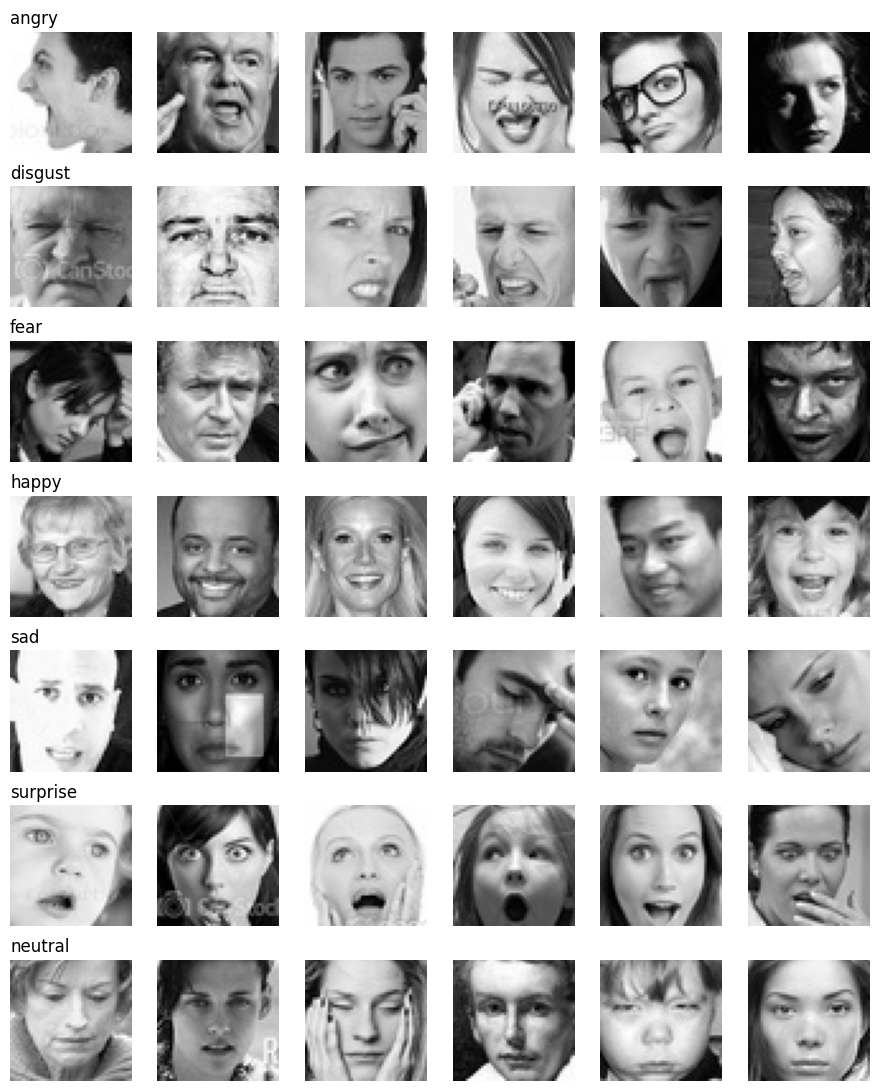

In [8]:
# show 6 random training images for each emotion
fig, axes = plt.subplots(7, 6, figsize=(9, 11))
for row, emo in enumerate(EMOTIONS):
    emo_paths = [p for p, lab in zip(train_paths, train_labels) if lab == emo]
    for col, p in enumerate(random.sample(emo_paths, 6)):
        axes[row, col].imshow(cv2.imread(p, cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(emo, loc="left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/sample_grid.png", dpi=150)
plt.show()

For the predict function demo at the end, I set aside 1 test image per emotion in the `unseen_images` folder. I also removed them from the test list, so they are not used for training or for the evaluation.

In [9]:
os.makedirs(UNSEEN_DIR, exist_ok=True)
unseen_rows = []
for i, emo in enumerate(EMOTIONS):
    emo_idx = [j for j, lab in enumerate(test_labels) if lab == emo]
    pick = random.choice(emo_idx)
    new_name = "unseen_%02d.jpg" % (i + 1)
    shutil.copy(test_paths[pick], os.path.join(UNSEEN_DIR, new_name))
    unseen_rows.append([new_name, test_paths[pick], emo])

unseen_df = pd.DataFrame(unseen_rows, columns=["file", "original", "true_label"])
unseen_df.to_csv(UNSEEN_DIR + "/unseen_labels.csv", index=False)

# remove them from the test set
picked = set(unseen_df["original"])
test_labels = [lab for p, lab in zip(test_paths, test_labels) if p not in picked]
test_paths = [p for p in test_paths if p not in picked]

print(unseen_df)
print("\nTest images left for evaluation:", len(test_paths))

            file                                    original true_label
0  unseen_01.jpg     data/test\angry\PublicTest_36659344.jpg      angry
1  unseen_02.jpg  data/test\disgust\PrivateTest_71883356.jpg    disgust
2  unseen_03.jpg     data/test\fear\PrivateTest_22969065.jpg       fear
3  unseen_04.jpg     data/test\happy\PublicTest_73176666.jpg      happy
4  unseen_05.jpg       data/test\sad\PublicTest_56874737.jpg        sad
5  unseen_06.jpg  data/test\surprise\PublicTest_39373170.jpg   surprise
6  unseen_07.jpg  data/test\neutral\PrivateTest_48418032.jpg    neutral

Test images left for evaluation: 7171


## Milestone 1 - Face Detection & Visual Check
I used OpenCV's Haar cascade for face detection. FER2013 images are only 48x48 and the face already fills the whole picture, so Haar missed a lot of faces at first (about 66% detected on a small test). Adding a 12px border around the image and making it 4x bigger before detecting raised that to about 82%. If no face is found, I just use the whole image, since FER2013 images are already cropped faces.

In [10]:
face_cascade = cv2.CascadeClassifier(HAAR_FILE)
print("Haar cascade loaded:", not face_cascade.empty())

def detect_face(gray):
    pad = 12
    scale = 4
    if max(gray.shape) > 200:   # bigger photos don't need padding or resizing
        pad = 0
        scale = 1

    img = cv2.copyMakeBorder(gray, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    img = cv2.equalizeHist(img)
    min_size = min(img.shape) // 4
    faces = face_cascade.detectMultiScale(img, scaleFactor=1.05, minNeighbors=4, minSize=(min_size, min_size))
    if len(faces) == 0:
        return None

    # if there is more than one face, take the biggest one
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

    # convert back to the coordinates of the original image
    x1 = max(int(x / scale) - pad, 0)
    y1 = max(int(y / scale) - pad, 0)
    x2 = min(int((x + w) / scale) - pad, gray.shape[1])
    y2 = min(int((y + h) / scale) - pad, gray.shape[0])
    if x2 - x1 < 5 or y2 - y1 < 5:
        return None
    return x1, y1, x2, y2

Haar cascade loaded: True


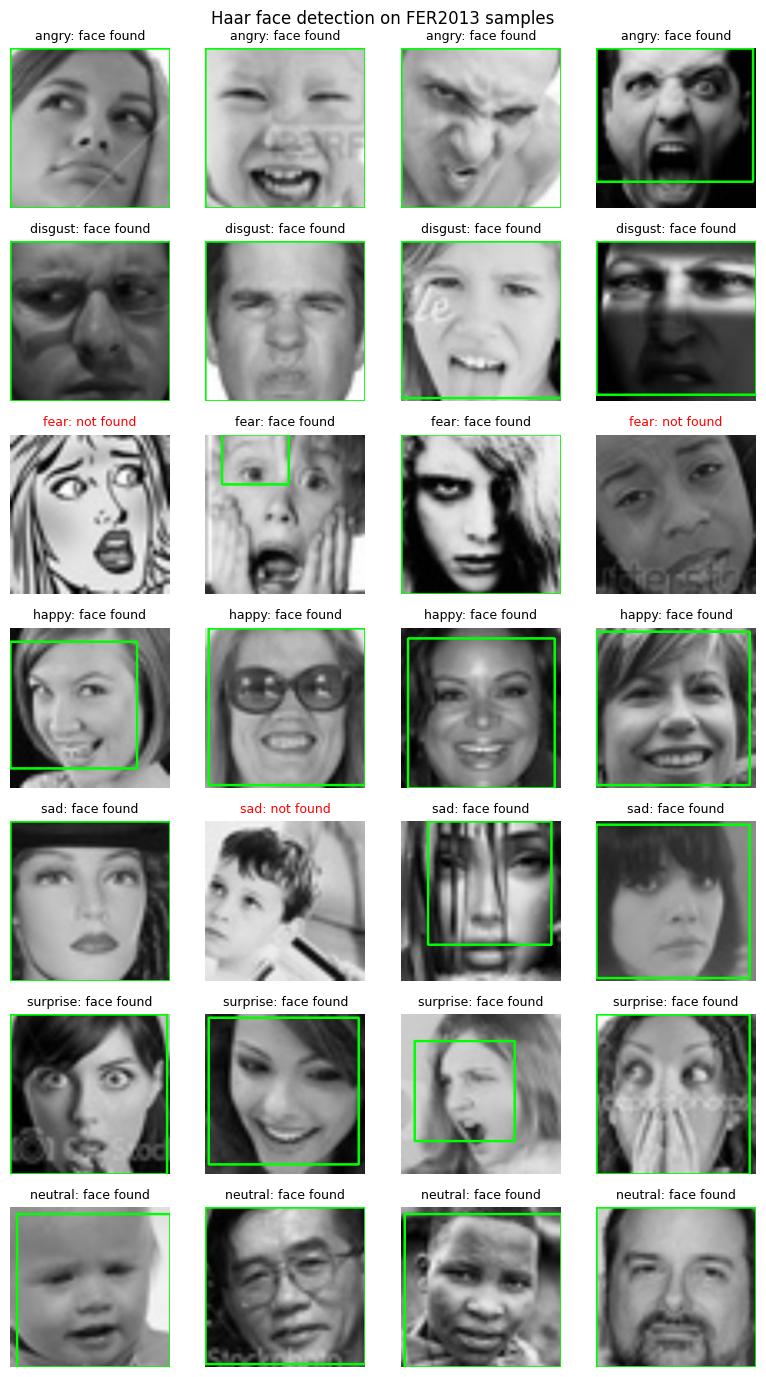

In [11]:
# draw the boxes on 4 random training images per emotion
fig, axes = plt.subplots(7, 4, figsize=(8, 14))
for row, emo in enumerate(EMOTIONS):
    emo_paths = [p for p, lab in zip(train_paths, train_labels) if lab == emo]
    for col, p in enumerate(random.sample(emo_paths, 4)):
        gray = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        box = detect_face(gray)
        show = cv2.resize(gray, (192, 192))       # bigger so the box is easier to see
        show = cv2.cvtColor(show, cv2.COLOR_GRAY2RGB)
        if box is not None:
            x1, y1, x2, y2 = box
            cv2.rectangle(show, (x1 * 4, y1 * 4), (x2 * 4, y2 * 4), (0, 255, 0), 2)
            axes[row, col].set_title(emo + ": face found", fontsize=9)
        else:
            axes[row, col].set_title(emo + ": not found", fontsize=9, color="red")
        axes[row, col].imshow(show)
        axes[row, col].axis("off")
plt.suptitle("Haar face detection on FER2013 samples")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/face_detection.png", dpi=150)
plt.show()

In [12]:
# detection rate using 100 random training images per emotion
rates = []
for emo in EMOTIONS:
    emo_paths = [p for p, lab in zip(train_paths, train_labels) if lab == emo]
    sample = random.sample(emo_paths, 100)
    found = 0
    for p in sample:
        if detect_face(cv2.imread(p, cv2.IMREAD_GRAYSCALE)) is not None:
            found += 1
    rates.append([emo, found])

print(pd.DataFrame(rates, columns=["emotion", "faces found (out of 100)"]))

    emotion  faces found (out of 100)
0     angry                        82
1   disgust                        90
2      fear                        80
3     happy                        82
4       sad                        66
5  surprise                        92
6   neutral                        80


## Milestone 2 - Feature Extraction (Track B: CNN deep features)
Steps for every image:
1. Detect the face and crop it (or use the whole image if no face was found).
2. Resize to 224x224, the input size MobileNetV2 was trained on.
3. Convert grayscale to 3 channels, because the CNN expects RGB.
4. Normalize with the ImageNet mean and std.
5. Pass it through the pretrained MobileNetV2 (no training, used only as a feature extractor), then average-pool the last layer. This gives **1280 features per image**.

Extraction takes about 20 minutes on my laptop (CPU only), so I save the features to the `features` folder and load them on later runs.

In [13]:
cnn = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V2)
cnn.eval()

MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def prepare_face(gray):
    box = detect_face(gray)
    if box is not None:
        x1, y1, x2, y2 = box
        face = gray[y1:y2, x1:x2]
    else:
        face = gray
    face = cv2.resize(face, (224, 224))
    face = cv2.cvtColor(face, cv2.COLOR_GRAY2RGB)   # 1 channel -> 3 channels
    face = face / 255.0
    face = (face - MEAN) / STD
    face = face.transpose(2, 0, 1)                  # (224, 224, 3) -> (3, 224, 224) for pytorch
    return face.astype(np.float32), box is not None

def get_embeddings(batch):
    x = torch.tensor(np.array(batch))
    with torch.no_grad():
        out = cnn.features(x)
        out = out.mean(dim=[2, 3])                  # global average pooling -> 1280 values
    return out.numpy()

In [14]:
def extract_features(paths, save_file, batch_size=128):
    if os.path.exists(save_file):
        print("Loading saved features from", save_file)
        data = np.load(save_file)
        return data["X"], data["found"]

    all_features = []
    found = []
    batch = []
    start = time.time()
    for i, p in enumerate(paths):
        gray = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        face, ok = prepare_face(gray)
        batch.append(face)
        found.append(ok)
        if len(batch) == batch_size:
            all_features.append(get_embeddings(batch))
            batch = []
        if (i + 1) % 5000 == 0:
            print(i + 1, "images done,", round(time.time() - start), "sec")
    if len(batch) > 0:
        all_features.append(get_embeddings(batch))

    X = np.vstack(all_features)
    found = np.array(found)
    np.savez(save_file, X=X, found=found)
    print("Saved", save_file, X.shape, "in", round(time.time() - start), "sec")
    return X, found

X_train, found_train = extract_features(train_paths, FEATURE_DIR + "/train_features.npz")
X_test, found_test = extract_features(test_paths, FEATURE_DIR + "/test_features.npz")
y_train = np.array(train_labels)
y_test = np.array(test_labels)

Loading saved features from features/train_features.npz


Loading saved features from features/test_features.npz


### Train-Test Split Check

In [15]:
print("X_train:", X_train.shape, "  y_train:", y_train.shape)
print("X_test: ", X_test.shape, "  y_test: ", y_test.shape)
total = len(y_train) + len(y_test)
print("Split: %.1f%% train / %.1f%% test" % (len(y_train) / total * 100, len(y_test) / total * 100))
print()
print("Face detected in train images: %.1f%%" % (found_train.mean() * 100))
print("Face detected in test images:  %.1f%%" % (found_test.mean() * 100))
print()
print(pd.DataFrame({"train": pd.Series(y_train).value_counts(),
                    "test": pd.Series(y_test).value_counts()}).loc[EMOTIONS])

X_train: (28709, 1280)   y_train: (28709,)
X_test:  (7171, 1280)   y_test:  (7171,)
Split: 80.0% train / 20.0% test

Face detected in train images: 81.3%
Face detected in test images:  81.3%

          train  test
angry      3995   957
disgust     436   110
fear       4097  1023
happy      7215  1773
sad        4830  1246
surprise   3171   830
neutral    4965  1232


## Model Training
I trained two models on the same CNN features:

* **Logistic Regression**: the features are standardized first (StandardScaler). I picked C on a validation set (10% of the training data) so the test set stays untouched. I used `class_weight="balanced"` because *disgust* has far fewer images than the other classes.
* **SVM (RBF kernel)**: StandardScaler, then PCA down to 256 dimensions, then SVC. I chose SVM over Random Forest because Random Forest doesn't do well on 1280 dense CNN features: each split only looks at one feature, and it overfits easily. An RBF SVM can draw curved boundaries between the classes and is commonly used on top of CNN embeddings. PCA makes the SVM train much faster while keeping most of the information.

I used random_state = 42 everywhere.

In [16]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1,
                                            stratify=y_train, random_state=SEED)

best_C = None
best_f1 = 0
val_rows = []
for C in [0.01, 0.1, 1]:
    lr = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced")),
    ])
    lr.fit(X_tr, y_tr)
    pred = lr.predict(X_val)
    f1 = f1_score(y_val, pred, average="macro")
    print("C =", C, " val accuracy = %.4f" % accuracy_score(y_val, pred), " val macro-F1 = %.4f" % f1)
    val_rows.append([C, round(accuracy_score(y_val, pred), 4), round(f1, 4)])
    if f1 > best_f1:
        best_f1 = f1
        best_C = C
print("Best C:", best_C)

pd.DataFrame(val_rows, columns=["C", "val_accuracy", "val_macro_f1"]).to_csv(OUTPUT_DIR + "/logreg_validation.csv", index=False)

C = 0.01  val accuracy = 0.4664  val macro-F1 = 0.4239


C = 0.1  val accuracy = 0.4678  val macro-F1 = 0.4235


C = 1  val accuracy = 0.4688  val macro-F1 = 0.4250
Best C: 1


In [17]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=best_C, max_iter=2000, class_weight="balanced")),
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=256, random_state=SEED)),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED)),
    ]),
}

train_times = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_times[name] = round(time.time() - start, 1)
    print("Trained", name, "in", train_times[name], "sec")

Trained Logistic Regression in 105.0 sec


Trained SVM (RBF) in 196.9 sec


## Milestone 3 - Evaluation

In [18]:
results = []
predictions = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    results.append([name, accuracy_score(y_test, y_pred), p, r, f1, train_times[name]])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1", "Train time (s)"])
results_df = results_df.set_index("Model").round(4)
results_df.to_csv(OUTPUT_DIR + "/model_comparison.csv")
print("Test images:", len(y_test))
print(results_df)

Test images: 7171
                     Accuracy  Macro-Precision  Macro-Recall  Macro-F1  \
Model                                                                    
Logistic Regression    0.4804           0.4276        0.4651    0.4356   
SVM (RBF)              0.5268           0.5030        0.5247    0.5100   

                     Train time (s)  
Model                                
Logistic Regression           105.0  
SVM (RBF)                     196.9  


In [19]:
for name, y_pred in predictions.items():
    print("=====", name, "=====")
    report = classification_report(y_test, y_pred, labels=EMOTIONS, digits=4, zero_division=0)
    print(report)
    with open(OUTPUT_DIR + "/report_" + name.split()[0].lower() + ".txt", "w") as f:
        f.write(report)

===== Logistic Regression =====
              precision    recall  f1-score   support

       angry     0.3613    0.3741    0.3676       957
     disgust     0.1553    0.4364    0.2291       110
        fear     0.3590    0.3050    0.3298      1023
       happy     0.6857    0.6497    0.6672      1773
         sad     0.4126    0.3676    0.3888      1246
    surprise     0.5550    0.6627    0.6041       830
     neutral     0.4644    0.4602    0.4623      1232

    accuracy                         0.4804      7171
   macro avg     0.4276    0.4651    0.4356      7171
weighted avg     0.4871    0.4804    0.4815      7171

===== SVM (RBF) =====
              precision    recall  f1-score   support

       angry     0.4151    0.4420    0.4281       957
     disgust     0.4040    0.5545    0.4674       110
        fear     0.4410    0.3216    0.3720      1023
       happy     0.7130    0.6475    0.6787      1773
         sad     0.4184    0.4567    0.4367      1246
    surprise     0.6598 

In [20]:
# save the per-class precision / recall / F1 of both models in one csv
rows = []
for name, y_pred in predictions.items():
    p, r, f1, support = precision_recall_fscore_support(y_test, y_pred, labels=EMOTIONS, zero_division=0)
    for i, emo in enumerate(EMOTIONS):
        rows.append([name, emo, round(p[i], 4), round(r[i], 4), round(f1[i], 4), support[i]])

per_class_df = pd.DataFrame(rows, columns=["model", "emotion", "precision", "recall", "f1", "support"])
per_class_df.to_csv(OUTPUT_DIR + "/per_class_metrics.csv", index=False)

# F1 of each emotion side by side
f1_table = per_class_df.pivot(index="emotion", columns="model", values="f1").loc[EMOTIONS]
f1_table.to_csv(OUTPUT_DIR + "/per_class_f1_comparison.csv")
print(f1_table)

model     Logistic Regression  SVM (RBF)
emotion                                 
angry                  0.3676     0.4281
disgust                0.2291     0.4674
fear                   0.3298     0.3720
happy                  0.6672     0.6787
sad                    0.3888     0.4367
surprise               0.6041     0.6926
neutral                0.4623     0.4946


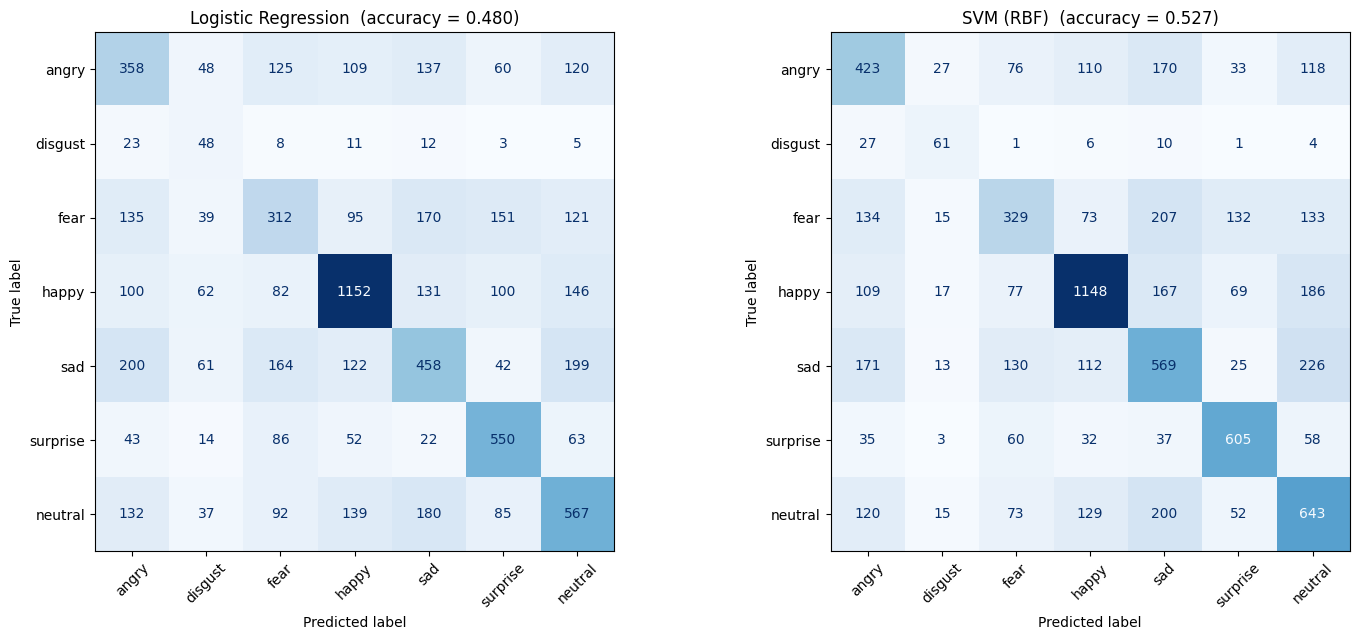

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=EMOTIONS, ax=ax,
                                            cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(name + "  (accuracy = %.3f)" % accuracy_score(y_test, y_pred))
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/confusion_matrices.png", dpi=150)
plt.show()

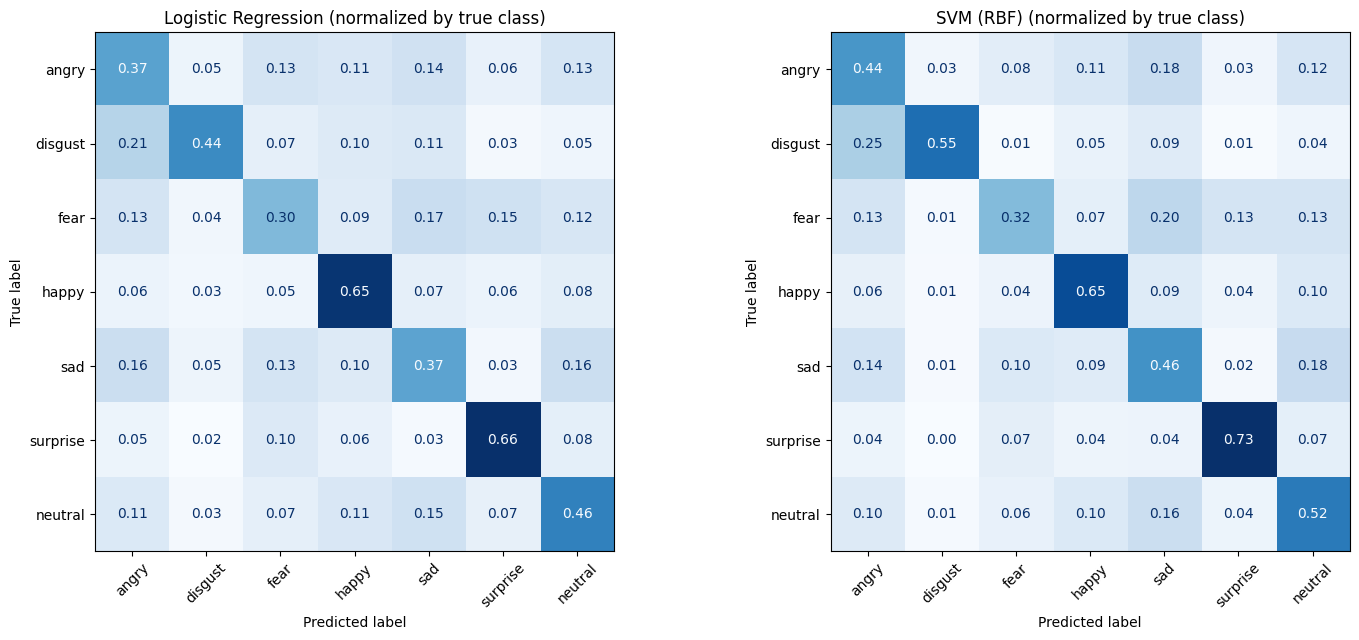

In [22]:
# the same matrices but as percentages of each true class, easier to compare
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=EMOTIONS, ax=ax, normalize="true",
                                            values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(name + " (normalized by true class)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/confusion_matrices_normalized.png", dpi=150)
plt.show()

In [23]:
# which emotions get mixed up the most?
confusion_rows = []
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=EMOTIONS, normalize="true")
    pairs = []
    for i in range(7):
        for j in range(7):
            if i != j:
                pairs.append((cm[i, j], EMOTIONS[i], EMOTIONS[j]))
    pairs.sort(reverse=True)
    print(name, "- top 5 confusions (true -> predicted):")
    for value, true_emo, pred_emo in pairs[:5]:
        print("   %-8s -> %-8s %.1f%%" % (true_emo, pred_emo, value * 100))
        confusion_rows.append([name, true_emo, pred_emo, round(value * 100, 1)])
    print()

    # also save the confusion matrix (counts) of each model
    short = name.split()[0].lower()
    counts_cm = confusion_matrix(y_test, y_pred, labels=EMOTIONS)
    pd.DataFrame(counts_cm, index=EMOTIONS, columns=EMOTIONS).to_csv(OUTPUT_DIR + "/confusion_matrix_" + short + ".csv")

pd.DataFrame(confusion_rows, columns=["model", "true", "predicted", "percent_of_true"]).to_csv(
    OUTPUT_DIR + "/top_confusions.csv", index=False)

Logistic Regression - top 5 confusions (true -> predicted):
   disgust  -> angry    20.9%
   fear     -> sad      16.6%
   sad      -> angry    16.1%
   sad      -> neutral  16.0%
   fear     -> surprise 14.8%

SVM (RBF) - top 5 confusions (true -> predicted):
   disgust  -> angry    24.5%
   fear     -> sad      20.2%
   sad      -> neutral  18.1%
   angry    -> sad      17.8%
   neutral  -> sad      16.2%



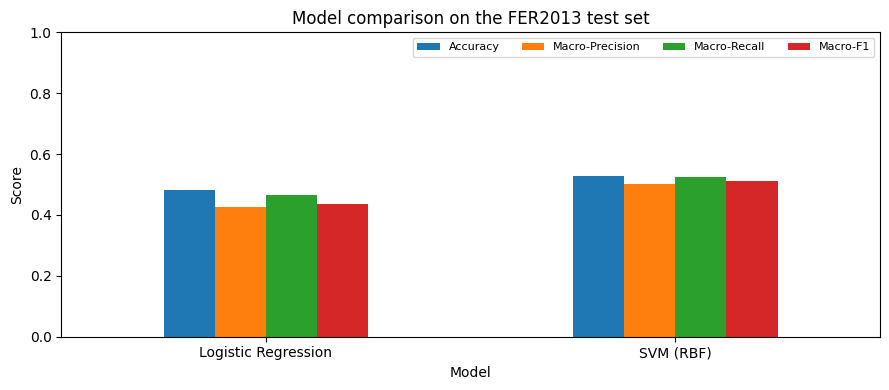

Better model (higher macro-F1): SVM (RBF)


In [24]:
results_df.drop(columns="Train time (s)").plot(kind="bar", figsize=(9, 4), rot=0)
plt.ylim(0, 1)
plt.title("Model comparison on the FER2013 test set")
plt.ylabel("Score")
plt.legend(loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/model_comparison.png", dpi=150)
plt.show()

best_name = results_df["Macro-F1"].idxmax()
best_model = models[best_name]
print("Better model (higher macro-F1):", best_name)

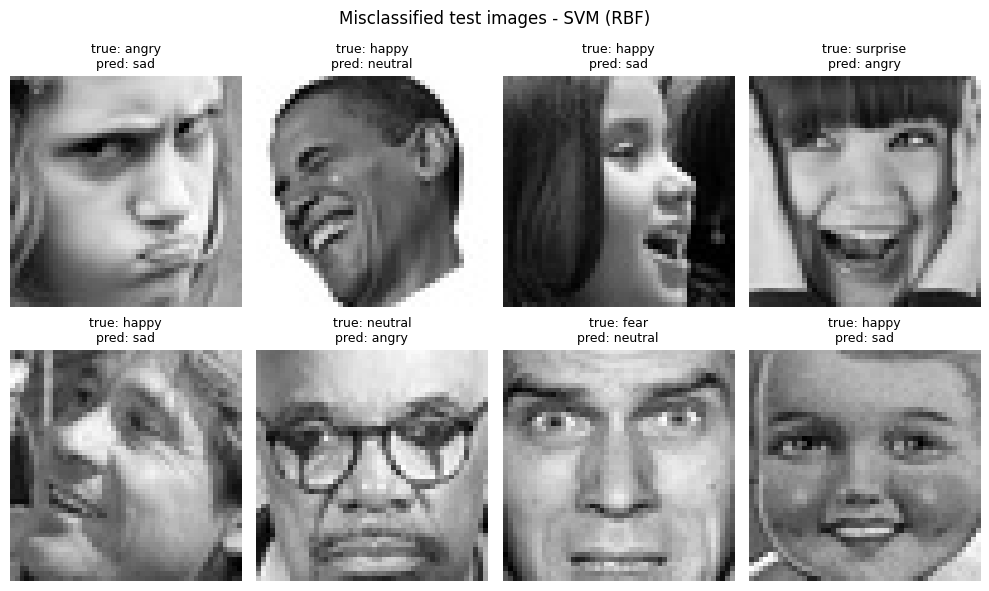

In [25]:
# some test images that the better model got wrong
wrong = [i for i in range(len(y_test)) if predictions[best_name][i] != y_test[i]]
examples = random.sample(wrong, 8)

fig, axes = plt.subplots(2, 4, figsize=(10, 6.2))
for ax, i in zip(axes.flatten(), examples):
    ax.imshow(cv2.imread(test_paths[i], cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax.set_title("true: " + y_test[i] + "\npred: " + predictions[best_name][i], fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified test images - " + best_name)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/misclassified_examples.png", dpi=150)
plt.show()

In [26]:
# save every test prediction of both models
pred_df = pd.DataFrame({
    "file": [os.path.relpath(p, TEST_DIR) for p in test_paths],
    "true": y_test,
    "logreg_pred": predictions["Logistic Regression"],
    "svm_pred": predictions["SVM (RBF)"],
})
pred_df["logreg_correct"] = pred_df["true"] == pred_df["logreg_pred"]
pred_df["svm_correct"] = pred_df["true"] == pred_df["svm_pred"]
pred_df.to_csv(OUTPUT_DIR + "/test_predictions.csv", index=False)

print("Saved", len(pred_df), "test predictions")
print("Both models correct:", (pred_df["logreg_correct"] & pred_df["svm_correct"]).sum())
print("Only SVM correct:   ", (~pred_df["logreg_correct"] & pred_df["svm_correct"]).sum())
print("Only LogReg correct:", (pred_df["logreg_correct"] & ~pred_df["svm_correct"]).sum())
print("Both wrong:         ", (~pred_df["logreg_correct"] & ~pred_df["svm_correct"]).sum())

Saved 7171 test predictions
Both models correct: 2817
Only SVM correct:    961
Only LogReg correct: 628
Both wrong:          2765


## Simple Deployment - predict function
`predict_emotion()` reads a new image, runs the same steps as training (face detection and crop, resize to 224x224, 3 channels, MobileNetV2 features), then uses the better model to output one of the 7 emotions.

In [27]:
def predict_emotion(image_path, model=best_model):
    gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        print("Could not read", image_path)
        return None
    face, found = prepare_face(gray)
    features = get_embeddings([face])
    return model.predict(features)[0]

unseen_01.jpg   predicted: happy     (true: angry)
unseen_02.jpg   predicted: disgust   (true: disgust)
unseen_03.jpg   predicted: happy     (true: fear)
unseen_04.jpg   predicted: happy     (true: happy)
unseen_05.jpg   predicted: sad       (true: sad)
unseen_06.jpg   predicted: fear      (true: surprise)
unseen_07.jpg   predicted: neutral   (true: neutral)

Correct: 4 out of 7


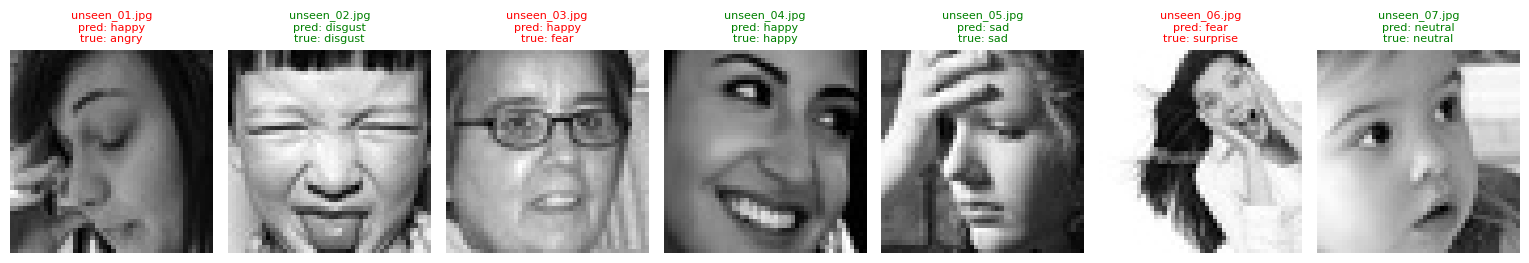

In [28]:
unseen_files = sorted(f for f in os.listdir(UNSEEN_DIR) if f.endswith(".jpg"))
true_labels = dict(zip(unseen_df["file"], unseen_df["true_label"]))

fig, axes = plt.subplots(1, len(unseen_files), figsize=(2.2 * len(unseen_files), 3))
correct = 0
unseen_results = []
for ax, f in zip(axes, unseen_files):
    path = os.path.join(UNSEEN_DIR, f)
    pred = predict_emotion(path)
    print("%-15s predicted: %-9s (true: %s)" % (f, pred, true_labels[f]))
    unseen_results.append([f, pred, true_labels[f], pred == true_labels[f]])
    if pred == true_labels[f]:
        correct += 1
    ax.imshow(cv2.imread(path, cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax.set_title(f + "\npred: " + pred + "\ntrue: " + true_labels[f], fontsize=8,
                 color="green" if pred == true_labels[f] else "red")
    ax.axis("off")
print("\nCorrect:", correct, "out of", len(unseen_files))
pd.DataFrame(unseen_results, columns=["file", "predicted", "true", "correct"]).to_csv(
    OUTPUT_DIR + "/unseen_predictions.csv", index=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/unseen_predictions.png", dpi=150)
plt.show()

## Reflection

**Results.** The SVM (RBF) did better than Logistic Regression on every metric: 52.7% accuracy and 0.510 macro-F1, compared with 48.0% and 0.436. Both models use the same MobileNetV2 features, so the gain comes from the classifier. An RBF kernel can separate classes that a linear model can't.

**Hardest classes.** Fear (F1 0.37 with SVM) and sad (0.44) were the hardest. Fear is often predicted as sad, surprise or angry, because a wide-open mouth or raised eyebrows can look like several emotions. Sad and neutral are also mixed up often, since both have a "flat" face with no big movement. Disgust has only 436 training images, so it was weak with Logistic Regression (F1 0.23). It improved a lot with the SVM (0.47), but a quarter of the disgust images were still predicted as angry, because both show a frown and a wrinkled nose.

**Errors.** Looking at the misclassified images, many have the head turned to the side, a hand covering part of the face, glasses, or a very small or blurry face. Some labels also look questionable to me (e.g. a "happy" face that looks more neutral). FER2013 is known to have noisy labels, and human accuracy on it is only around 65%.

**Possible improvements.**
- Fine-tune the CNN on FER2013 instead of only using frozen ImageNet features. ImageNet features were learned for objects, not facial expressions.
- Use data augmentation (flips, small rotations) and oversample disgust to deal with the class imbalance.
- Use a better face detector (e.g. MediaPipe) and align the faces using the eye positions.
- Combine the CNN features with landmark features from Track A (eye/mouth ratios), which are more interpretable.
- Tune the SVM's C and gamma with cross-validation. I used the default values because each SVM fit takes several minutes on my CPU.